# hpc_perf3: gap filling, performance and diagnostics

Archived Out-of-Africa simulations on chr20p (28.1 Mb), with 1% genotype
error: **50, 500 and 5,000 diploid samples**. Each cohort compares Full HMM
with greedy stitching at AF ≤ 0.1. The minimum retained focal length is the
mean-density equivalent of **25, 50 and 100 kb**, respectively. These are
different cohorts, simulation seeds and length filters, so sample-size trends
do not isolate the effect of increasing sample size.

Each setting has **one trial**, with 94 matching workers. Lines connect
observations; they do not estimate replicate uncertainty. Timing starts from
prepared ancestor references and includes input loading, setup, matching and
output; ancestor inference and allele validation are outside this window.

All inputs come from `data/ch5/hpc_perf3_diagnostics/` (extract the adjacent
`.tar.gz` there if needed). Tables, dated trees and PNG/PDF figures are cached
under its `for_plots/` directory. No genotype stores or ARG metrics are used.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

/Users/duncan/work/dphil-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "cache_subdir": "for_plots",
    "workers": None,
    "helper_threads": 1,
    "dating": {
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
    },
    "frequency_bins": {
        "cutoffs": [0.01, 0.5],
        "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
    },
    "title": "hpc_perf3",
    "description": "Out-of-Africa simulations · chr20p · 1% genotype error",
    "data_dir": repository_dir / "data/ch5/hpc_perf3_diagnostics",
    "mutation_rate": 2.35e-08,
    "population_groups": {"African": ["YRI"], "Non-African": ["CEU", "CHB"]},
    "stages": {
        "gap_parent": "gap_matching_assembly",
        "gap_children": [
            "gap_native_find_path",
            "gap_path_conversion",
            "gap_mutation_extraction",
            "gap_final_concatenation",
        ],
    },
}
config_path["base_dir"] = repository_dir
config = nb_utils.paramsearch_load_config(config_path)
plot_data = nb_utils.prepare_scaling_data(config)
logging.basicConfig(level=logging.INFO, format="%(message)s")

## Archived run checks

Sample counts come from saved cohort identities. Saved quality checks verify
called alleles and sample/reference metadata; they do not establish genealogy
accuracy. The resolved site-count minimum is included below. Diagnostic
coverage uses the observed inference-site extent, excluding chromosome flanks.

In [3]:
if __name__ == "__main__":
    cohorts = nb_utils.cohort_table(config)
    performance = nb_utils.performance_runs(config)
    summary = nb_utils.diagnostic_summary(config)
    ipython_display.display(cohorts)
    columns = [
        "num_samples",
        "method",
        "af_cutoff",
        "wall_s",
        "wall_ms_per_haplotype",
        "speedup",
        "effective_cores",
        "trial_peak_private_gib",
    ]
    ipython_display.display(performance[columns].round(3))

,dataset,num_samples,num_haplotypes,num_sites,analysis_span_mb,has_truth,min_region_size_kb,min_focal_region_size
0,out_of_africa_n50_28_1mbp_error,50,100,94665,28.017828,True,25,84
1,out_of_africa_n500_28_1mbp_error,500,1000,207968,28.018744,True,50,371
2,out_of_africa_n5000_28_1mbp_error,5000,10000,490670,28.018831,True,100,1751


,num_samples,method,af_cutoff,wall_s,wall_ms_per_haplotype,speedup,effective_cores,trial_peak_private_gib
0,50,full_hmm,NaN,5.094,50.943,1.000,2.672,1.242
1,50,greedy,0.1,70.386,703.865,0.072,1.815,1.554
2,500,full_hmm,NaN,19.556,19.556,1.000,31.358,4.900
3,500,greedy,0.1,74.096,74.096,0.264,6.263,44.919
5,5000,full_hmm,NaN,563.171,56.317,1.000,82.914,21.602
4,5000,greedy,0.1,302.608,30.261,1.861,48.393,109.135


## Performance against sample size

Wall time is the measured end-to-end window. Throughput divides that wall
time by the number of matched haplotypes at fixed worker count. Private memory
is sampled **sum of process-tree USS**, not RSS; shared mappings are not
multiplied by the number of workers. Whole-trial memory also covers work
outside the wall timer, including validation; timed-window memory covers the
same window as wall time. Average cores = (user + system CPU seconds) / wall seconds.
Speedup = Full HMM wall time / method wall time within the same cohort.
The dotted parallelism line marks the 94 matching workers. This is achieved
CPU concurrency, not speedup relative to a single-worker run. Setup and I/O
inside the measured window are included, as in the chapter 3 CPU/wall metric.
The sample-size axis is logarithmic; every measured size is labelled.

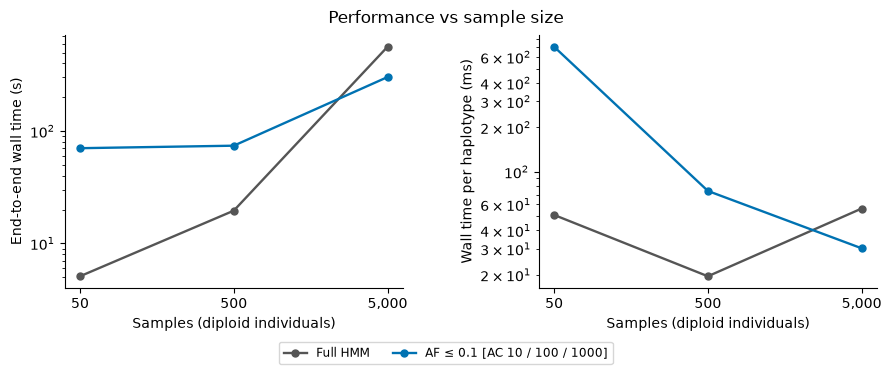

In [4]:
if __name__ == "__main__":
    metrics = {
        "wall_s": "End-to-end wall time (s)",
        "wall_ms_per_haplotype": "Wall time per haplotype (ms)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Performance vs sample size",
            include_full=True,
            log_y=True,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_wall_throughput",
        export_dpi=180,
    )

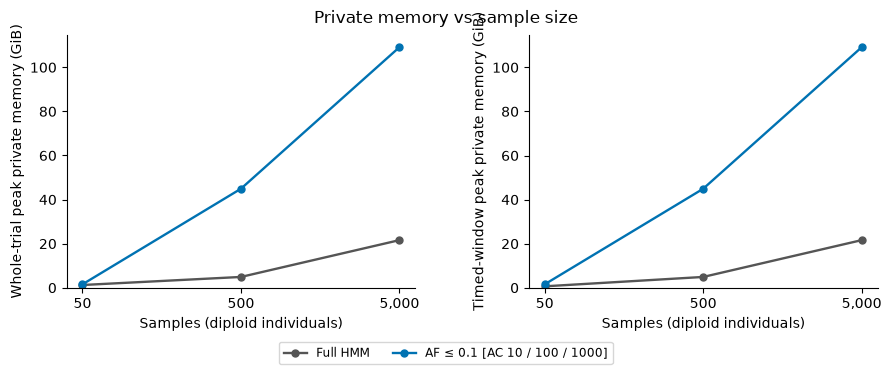

In [5]:
if __name__ == "__main__":
    metrics = {
        "trial_peak_private_gib": "Whole-trial peak private memory (GiB)",
        "window_peak_private_gib": "Timed-window peak private memory (GiB)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Private memory vs sample size",
            include_full=True,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_memory",
        export_dpi=180,
    )

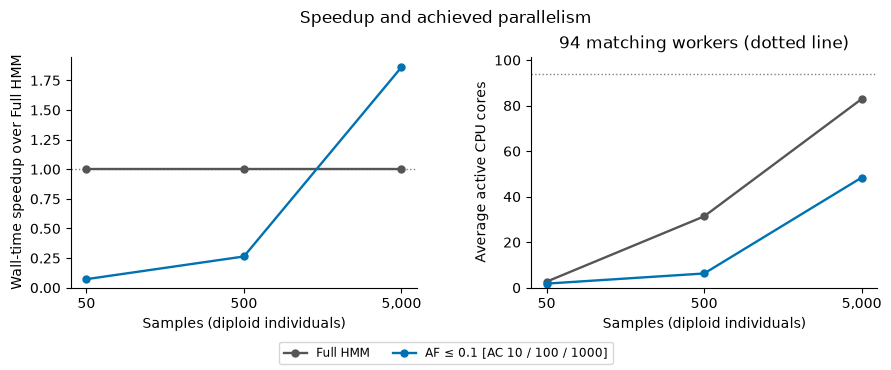

In [6]:
if __name__ == "__main__":
    metrics = {
        "speedup": "Wall-time speedup over Full HMM",
        "effective_cores": "Average active CPU cores",
    }
    figure = nb_plot.plot_scaling(
        plot_data,
        performance,
        metrics,
        "Speedup and achieved parallelism",
        include_full=True,
        cohort_labels={},
        cutoff_colors=["#0072B2"],
        full_color="#555555",
        line_width=1.7,
        marker="o",
        marker_size=5,
        method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
        method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
        panel_height=3.6,
        panel_width=4.4,
        range_margin=0.08,
        real_data_marker="o",
        sample_tick_alignments={
            "tgp_chr20p_n3202": "right",
            "out_of_africa_n5000_28_1mbp_error": "left",
        },
        sample_tick_rotation=0,
    )
    workers = config["experiment"]["performance"]["worker_counts"][0]
    nb_plot.plot_performance_against_sample_size(
        figure=figure, workers=workers, color="gray", linestyle=":", linewidth=1
    )
    nb_plot.save_cohort_figure(
        plot_data, figure, "performance_speedup_parallelism", export_dpi=180
    )

## Where greedy matching spends its time

The first stack partitions end-to-end wall time into sequential coordinator
and process phases. Matching/drain includes sample loading, result waiting
and assembly: its nested timers are not stacked again. Worker packing and
setup can overlap with coordinator phases; only the coordinator's elapsed
windows appear in this plot. The residual makes each stack equal the measured
trial total. In particular, startup and shutdown dominate the smallest run.

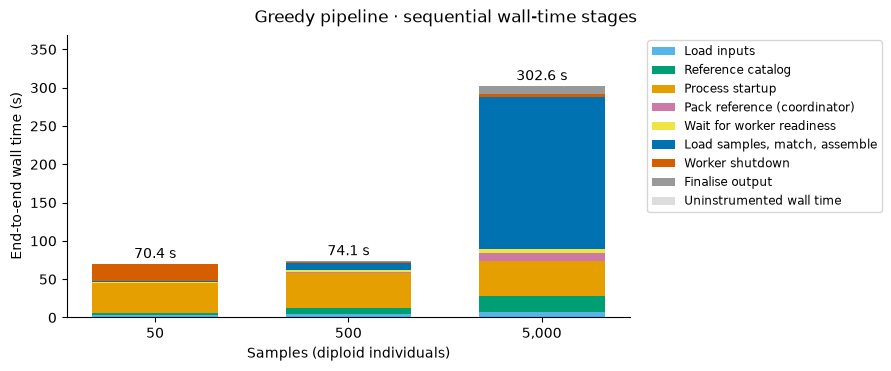

,num_samples,stage,wall_s,service_s
8,50,first_sample_slab_latency,1.338,NaN
9,50,sample_loading_remapping,NaN,1.338
10,50,first_result_latency,1.368,NaN
18,50,coordinator_matching_drain,1.412,NaN
29,500,first_sample_slab_latency,7.401,NaN
30,500,sample_loading_remapping,NaN,7.400
31,500,first_result_latency,7.588,NaN
39,500,coordinator_matching_drain,9.852,NaN
50,5000,first_sample_slab_latency,61.906,NaN
51,5000,sample_loading_remapping,NaN,61.906


In [7]:
if __name__ == "__main__":
    stages = nb_utils.stage_breakdown(config, performance)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_wall_stages(
            plot_data,
            stages,
            bar_width=0.65,
            cohort_labels={},
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            wall_stages={
                "input_setup": {"label": "Load inputs", "color": "#56B4E9"},
                "reference_catalog": {"label": "Reference catalog", "color": "#009E73"},
                "coordinator_process_startup": {
                    "label": "Process startup",
                    "color": "#E69F00",
                },
                "coordinator_packing_completion": {
                    "label": "Pack reference (coordinator)",
                    "color": "#CC79A7",
                },
                "coordinator_worker_readiness": {
                    "label": "Wait for worker readiness",
                    "color": "#F0E442",
                },
                "coordinator_matching_drain": {
                    "label": "Load samples, match, assemble",
                    "color": "#0072B2",
                },
                "coordinator_shutdown": {
                    "label": "Worker shutdown",
                    "color": "#D55E00",
                },
                "finalise_output": {"label": "Finalise output", "color": "#999999"},
                "other": {"label": "Uninstrumented wall time", "color": "#DDDDDD"},
            },
        ),
        "greedy_wall_stages",
        export_dpi=180,
    )
    latency_stages = [
        "sample_loading_remapping",
        "first_sample_slab_latency",
        "first_result_latency",
        "coordinator_matching_drain",
    ]
    latency = stages.recorded.loc[stages.recorded.stage.isin(latency_stages)]
    ipython_display.display(
        latency[["num_samples", "stage", "wall_s", "service_s"]].round(3)
    )

The next plot separates worker elapsed time from worker thread CPU time,
dividing each summed stage by the number of matched haplotypes. Gap HMM
`find_path`, path conversion, mutation extraction and concatenation replace
the inclusive gap timer; their remainder is shown as other gap work. These
worker totals overlap in wall time and are **not wall-time decompositions**.
Reference packing and worker setup are amortised over matched haplotypes.
Loader timings are shown separately in the table above.

**Per-sample timings are unavailable:** the archive retains aggregate stage
totals and call counts, without timings keyed by sample or haplotype. The
per-haplotype values here are workload averages, not individual measurements;
a coverage-versus-time scatter plot cannot be recovered from these totals.

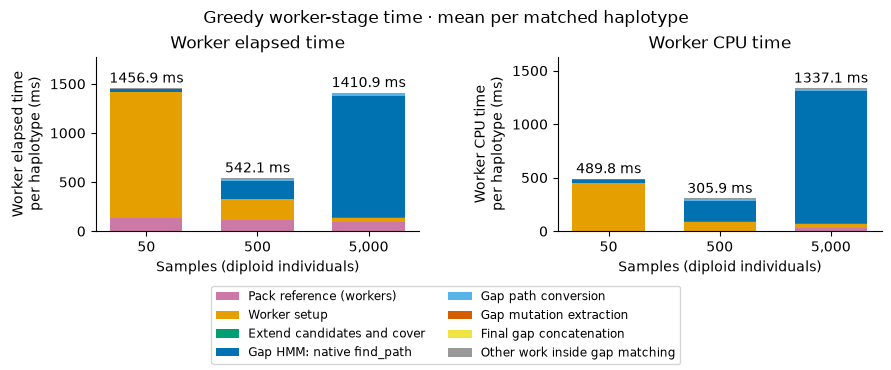

In [8]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_worker_stages(
            plot_data,
            stages,
            bar_width=0.65,
            cohort_labels={},
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            worker_stages={
                "reference_packing": {
                    "label": "Pack reference (workers)",
                    "color": "#CC79A7",
                },
                "worker_setup": {"label": "Worker setup", "color": "#E69F00"},
                "candidate_extension_cover": {
                    "label": "Extend candidates and cover",
                    "color": "#009E73",
                },
                "gap_native_find_path": {
                    "label": "Gap HMM: native find_path",
                    "color": "#0072B2",
                },
                "gap_path_conversion": {
                    "label": "Gap path conversion",
                    "color": "#56B4E9",
                },
                "gap_mutation_extraction": {
                    "label": "Gap mutation extraction",
                    "color": "#D55E00",
                },
                "gap_final_concatenation": {
                    "label": "Final gap concatenation",
                    "color": "#F0E442",
                },
                "gap_other": {
                    "label": "Other work inside gap matching",
                    "color": "#999999",
                },
            },
        ),
        "greedy_worker_stages",
        export_dpi=180,
    )

## Recorded workload

Focal site coverage uses the timed runner's summed focal/domain site counts,
rather than physical spans. Gap calls count separate HMM invocations. These
are workload measures, not timing decompositions.

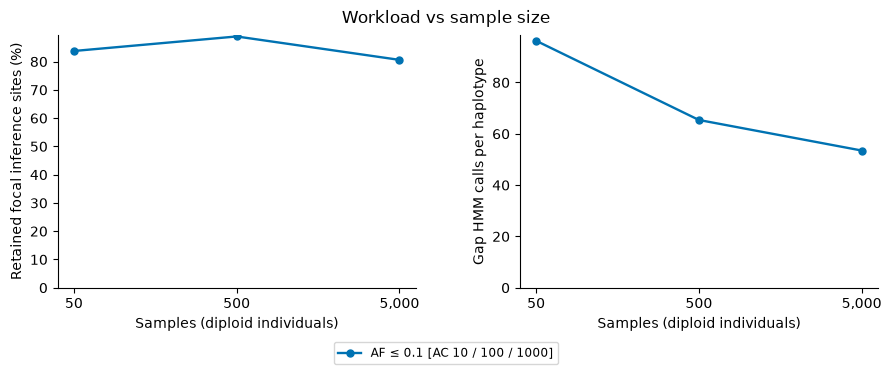

In [9]:
if __name__ == "__main__":
    metrics = {
        "focal_site_coverage_percentage": "Retained focal inference sites (%)",
        "gap_calls_per_haplotype": "Gap HMM calls per haplotype",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Workload vs sample size",
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "workload_scaling",
        export_dpi=180,
    )

## Extra switches and parent agreement

Each diagnostic mean weights haplotypes equally. Error bars are one
haplotype SEM within a cohort; paired haplotypes are dependent and these are
not simulation or benchmark replicate errors. Percentage switch increases
are calculated per haplotype before averaging. Parent agreement denominators
are evaluated inference sites in focal regions or gaps. Its y axes cover the
displayed means and SEMs rather than starting at zero.

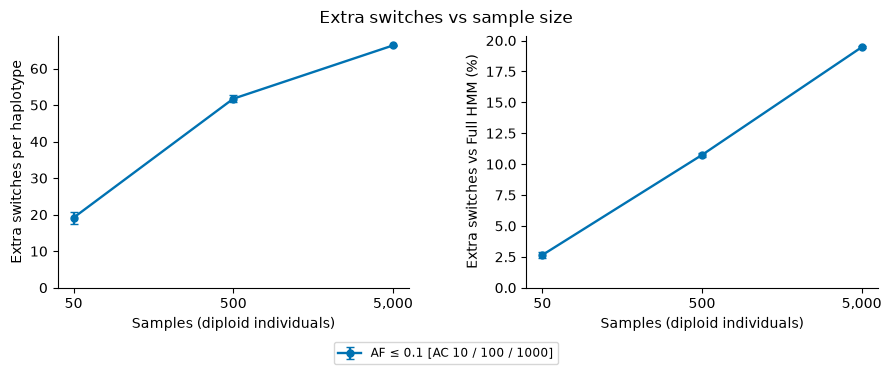

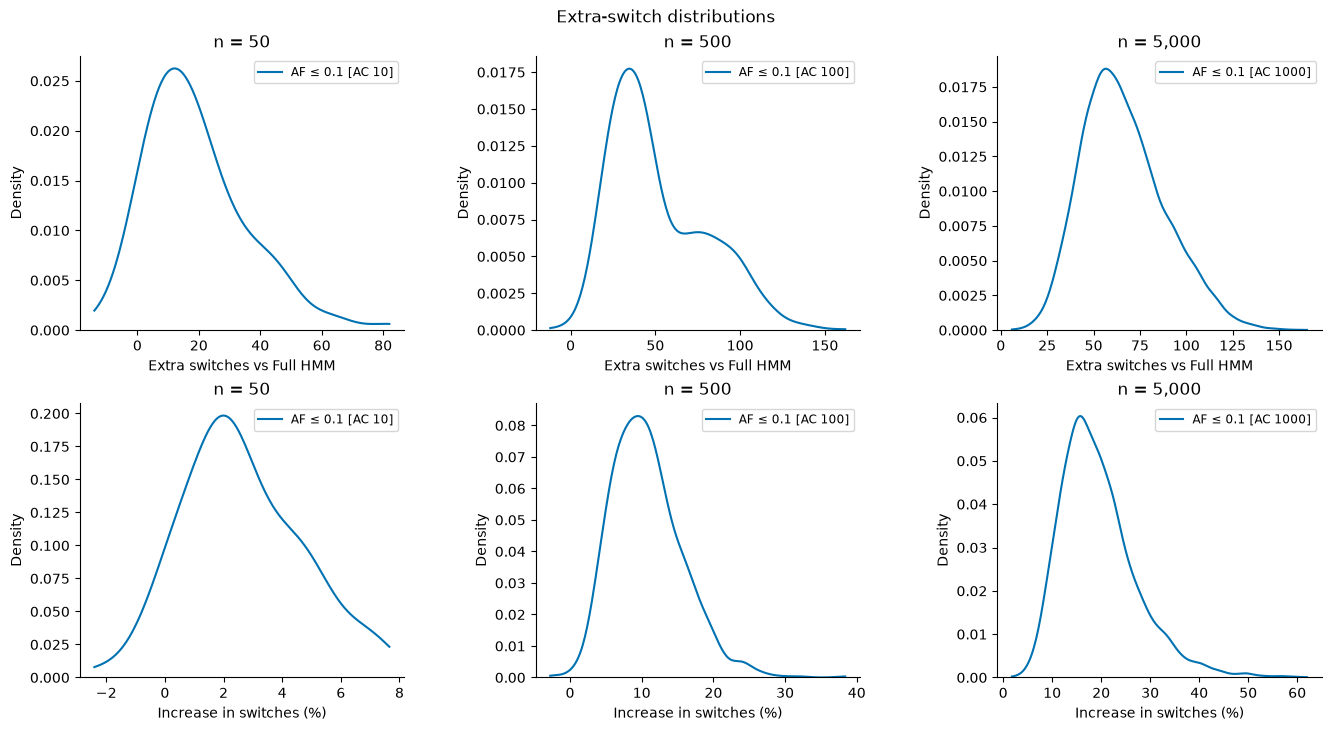

In [10]:
if __name__ == "__main__":
    metrics = {
        "num_extra_switches_mean": "Extra switches per haplotype",
        "switch_increase_percentage_mean": "Extra switches vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Extra switches vs sample size",
            sem=True,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "extra_switches_scaling",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_extra_switch_distributions(
            plot_data,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            kde_grid_size=256,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "extra_switch_distributions",
        export_dpi=180,
    )

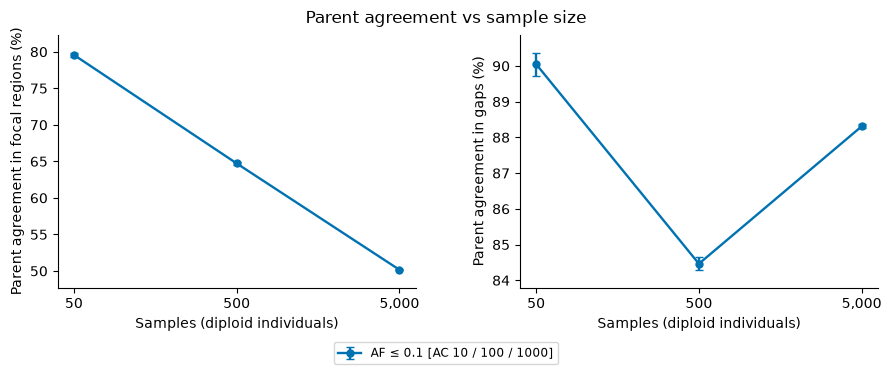

In [11]:
if __name__ == "__main__":
    metrics = {
        "focal_agreement_percentage_mean": "Parent agreement in focal regions (%)",
        "gap_agreement_percentage_mean": "Parent agreement in gaps (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Parent agreement vs sample size",
            sem=True,
            zoom=True,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "parent_agreement_scaling",
        export_dpi=180,
    )

## Physical focal coverage and region lengths

Population groups follow the analysis config. Curves show physical coverage
over the archived analysis extent, with one haplotype SEM. Histograms show
**retained** connected focal regions at the cohort-specific minimum;
unfiltered regions were not archived. `num_bins` is directly editable below.
Dashed site thresholds are the actual filters. The physical-length markers
are mean-density equivalents, not strict physical cutoffs for each region.

Reflected Scott KDEs use every interval, including tails outside the displayed
pooled 99th percentile. Legends report the omitted tail fraction. Site and
physical lengths are cached as lossless frequency tables. Gap plots use
density curves and dashed median markers, with no histogram or coverage plot.

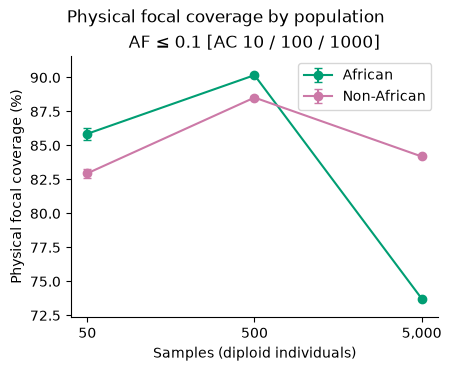

In [12]:
if __name__ == "__main__":
    population_coverage = nb_utils.population_coverage(config)
    lengths = nb_utils.perf_scaling_length_counts(config)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_coverage(
            plot_data,
            population_coverage,
            cohort_labels={},
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
            population_colors={"African": "#009E73", "Non-African": "#CC79A7"},
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "focal_population_coverage",
        export_dpi=180,
    )

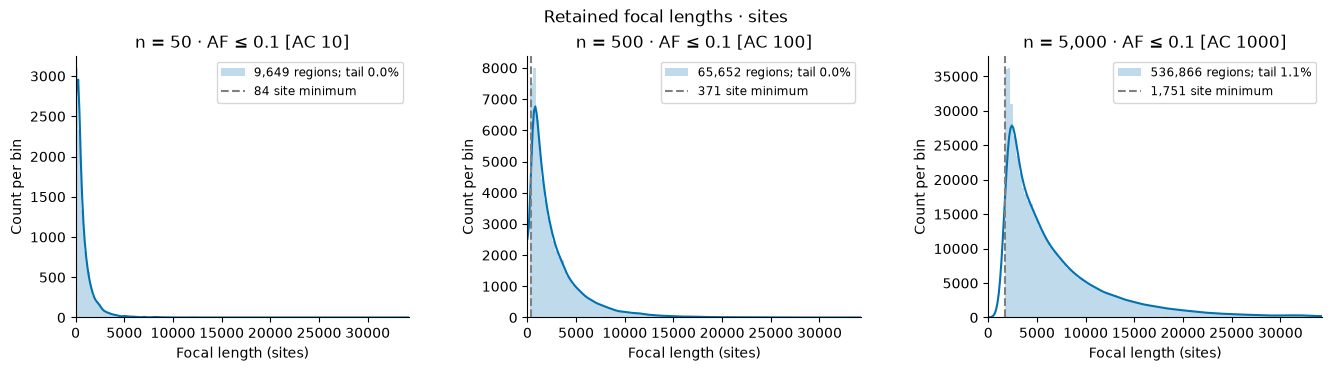

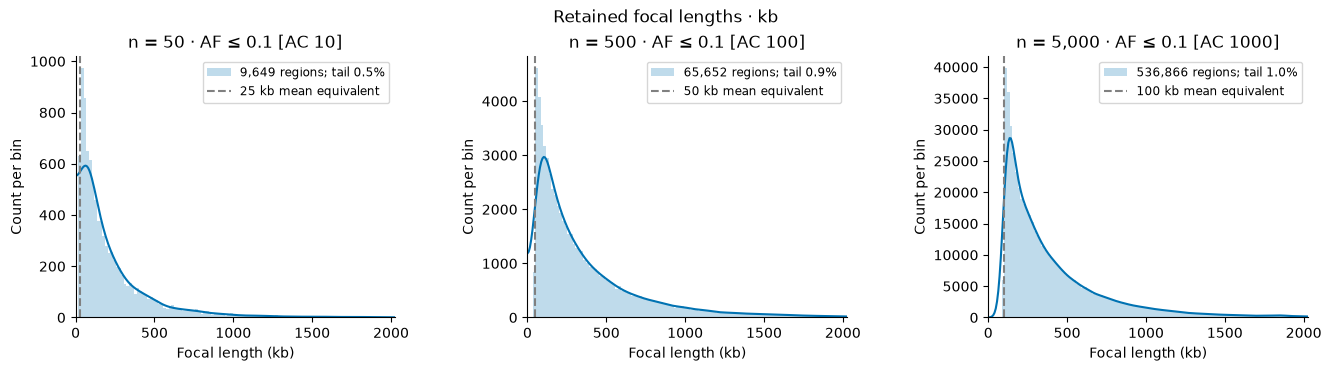

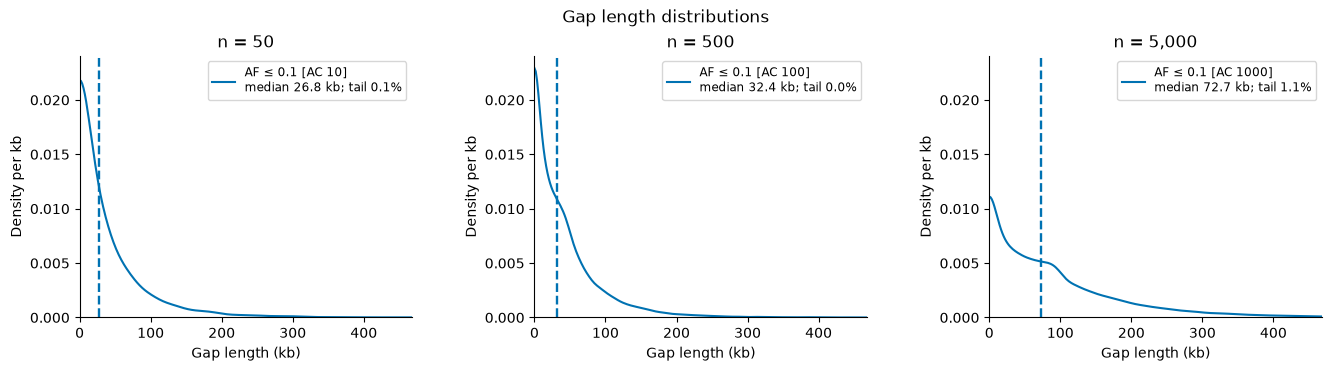

In [13]:
if __name__ == "__main__":
    num_bins = 120
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="sites",
            num_bins=num_bins,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "focal_lengths_sites",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="kb",
            num_bins=num_bins,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "focal_lengths_kb",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_gap_lengths(
            plot_data,
            lengths,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            kde_grid_size=256,
            length_display_quantile=0.99,
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "gap_lengths_kb",
        export_dpi=180,
    )

### Recurrent sites

A recurrent site contains **two or more mutation records**, including back
mutations. Compare saved raw Full HMM and stitched trees before simplification
or dating, with truth restricted to the same archived inference-site positions.
Raw inferred trees retain reference ancestry, as in the tree-count plots below.
Counts use `np.bincount(ts.mutations_site)` rather than decoding genotypes.

The left panel counts recurrent sites; brackets above each bar give their
percentage of **all saved inference sites** in that cohort. The right panel
gives the mean number of mutation records **conditional on a site being
recurrent**, including the first event. Truth has no genotype errors; the
inferred trees were reconstructed from the error-containing calls.
Full HMM has no recurrent sites here, so its conditional mean is undefined
and has no bar in the right panel.

Recurrent sites: out_of_africa_n50_28_1mbp_error


Recurrent sites: out_of_africa_n500_28_1mbp_error


Recurrent sites: out_of_africa_n5000_28_1mbp_error


,dataset,method,af_cutoff,num_sites,recurrent_sites,recurrent_site_percentage,mutations_at_recurrent_sites,mean_mutations_per_recurrent_site,additional_mutations,num_samples
0,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94665,0,0.000,0,NaN,0,50
1,out_of_africa_n50_28_1mbp_error,greedy,0.1,94665,3816,4.031,7979,2.091,4163,50
2,out_of_africa_n50_28_1mbp_error,truth,NaN,94665,337,0.356,675,2.003,338,50
3,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207968,0,0.000,0,NaN,0,500
4,out_of_africa_n500_28_1mbp_error,greedy,0.1,207968,24815,11.932,69044,2.782,44229,500
5,out_of_africa_n500_28_1mbp_error,truth,NaN,207968,1787,0.859,3578,2.002,1791,500
6,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490670,0,0.000,0,NaN,0,5000
7,out_of_africa_n5000_28_1mbp_error,greedy,0.1,490670,50510,10.294,322063,6.376,271553,5000
8,out_of_africa_n5000_28_1mbp_error,truth,NaN,490670,7735,1.576,15528,2.007,7793,5000


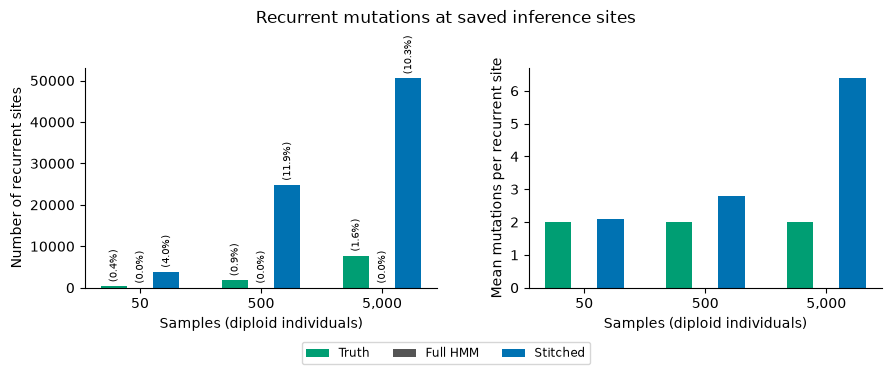

In [14]:
if __name__ == "__main__":
    recurrence = nb_utils.recurrent_sites(config)
    ipython_display.display(recurrence.round(3))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_recurrence(
            plot_data,
            recurrence,
            bar_width=0.65,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            truth_color="#009E73",
        ),
        "recurrent_sites",
        export_dpi=180,
    )

## Switch composition

Switches partition into within-focal, within-gap and seam categories. For
each AF and cohort, Full HMM is partitioned with that same focal mask; its
total does not change with the mask. All columns display their y-axis ticks.

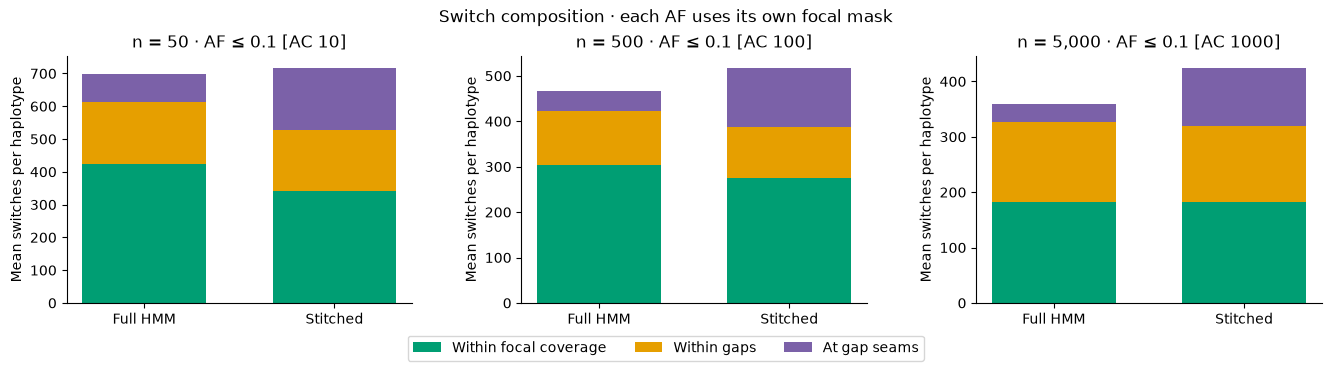

In [15]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_switch_composition(
            plot_data,
            summary,
            bar_width=0.65,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            switch_categories=["focal", "gap", "seam"],
            switch_colors=["#009E73", "#E69F00", "#7B61A8"],
            switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
        ),
        "switch_composition",
        export_dpi=180,
    )

## Direct ultimate-root to sample edges

These are raw copying edges from the ultimate ancestor (the child of the
vestigial root) directly to sample haplotypes, before root splitting or dating.
Count each edge once if it overlaps the common archived analysis extent;
its span is the number of observed base pairs, excluding chromosome flanks.
Counts and summed spans are divided by the cohort's haplotype count.

Each AF uses its own focal mask for **both** Full HMM and stitched paths.
An edge is **at a seam** if it overlaps a gap and contains an internal
focal/gap boundary, including either edge endpoint. An edge in a gap with
no such boundary is **gap interior**. Remaining edges are **focal only**.
Chromosome/domain ends are not seams. Edges spanning multiple regions are
counted once with seam classification taking precedence.

The difference panels subtract Full HMM from stitched within each category;
these are signed aggregate differences, not a pairing of individual edges.
Positive and negative contributions are stacked separately, with a diamond
marking the net difference. Moving an edge between categories can therefore
create opposite contributions even without changing the total edge count.

Histograms use common logarithmic bins over the **complete** observed span
range. Stitched bars are stacked by location; Full HMM is the outline. Both
axes are logarithmic, and counts are edges per haplotype per bin.

Root/sample edges: out_of_africa_n50_28_1mbp_error


Root/sample edges: out_of_africa_n500_28_1mbp_error


Root/sample edges: out_of_africa_n5000_28_1mbp_error


,num_samples,af_cutoff,method,category,edge_count,span_bp,edge_count_per_haplotype,span_kb_per_haplotype
0,50,0.1,full_hmm,seam,724,1968104.0,7.240,19.681
1,50,0.1,full_hmm,gap_interior,496,1796435.0,4.960,17.964
2,50,0.1,full_hmm,focal,622,1033301.0,6.220,10.333
3,50,0.1,greedy,seam,1784,2226903.0,17.840,22.269
4,50,0.1,greedy,gap_interior,491,1781959.0,4.910,17.820
5,50,0.1,greedy,focal,0,0.0,0.000,0.000
6,500,0.1,full_hmm,seam,3667,6831871.0,3.667,6.832
7,500,0.1,full_hmm,gap_interior,1688,3064507.0,1.688,3.065
8,500,0.1,full_hmm,focal,4057,7360007.0,4.057,7.360
9,500,0.1,greedy,seam,10799,6068569.0,10.799,6.069


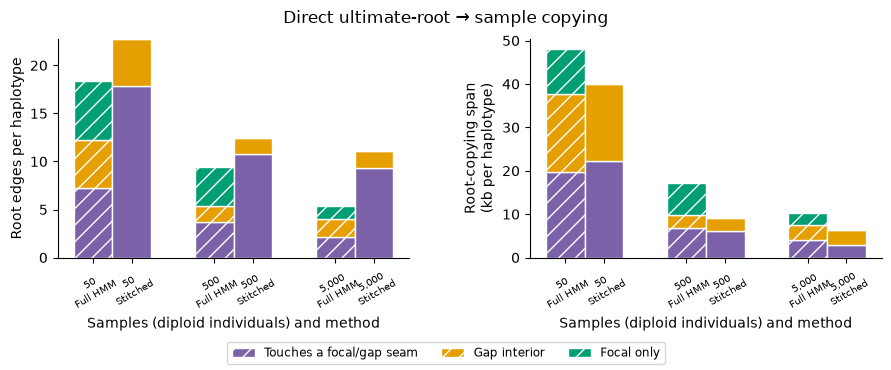

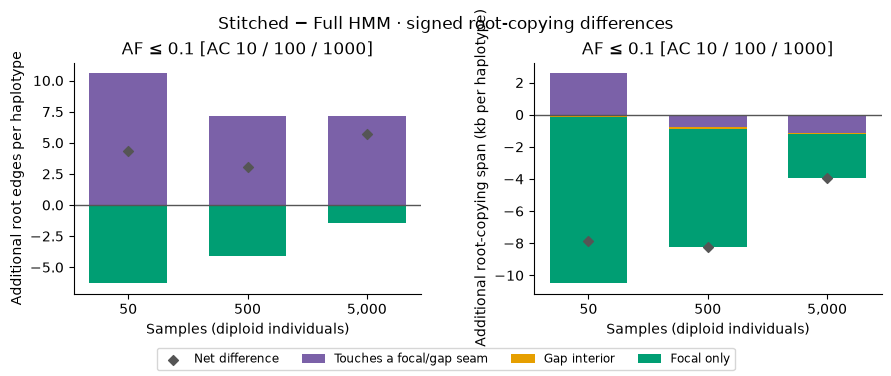

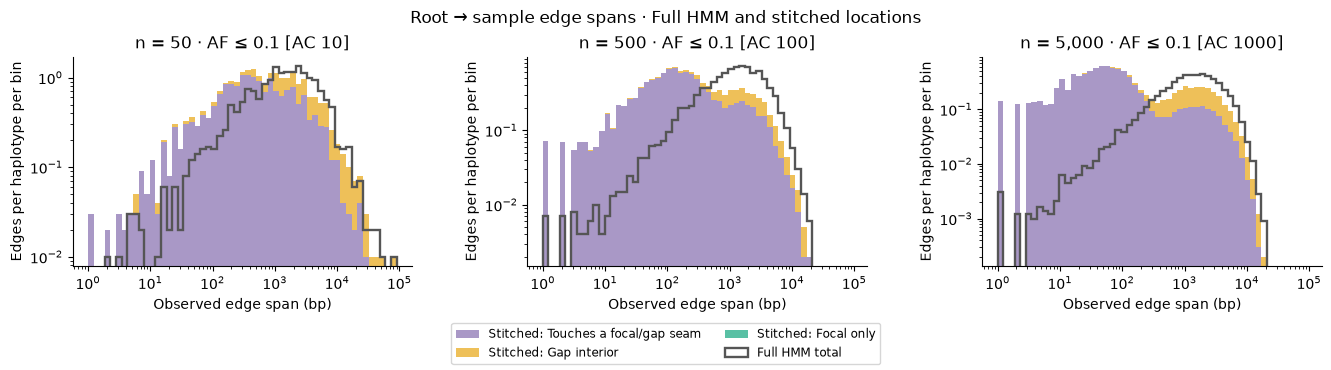

In [16]:
if __name__ == "__main__":
    root_edges = nb_utils.root_edge_summary(config)
    columns = [
        "num_samples",
        "af_cutoff",
        "method",
        "category",
        "edge_count",
        "span_bp",
        "edge_count_per_haplotype",
        "span_kb_per_haplotype",
    ]
    ipython_display.display(root_edges[columns].round(3))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_totals(
            plot_data,
            root_edges,
            cohort_labels={},
            grouped_bar_width=0.32,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_counts_spans",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_differences(
            plot_data,
            root_edges,
            bar_width=0.65,
            cohort_labels={},
            full_color="#555555",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_additional",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_spans(
            plot_data,
            cohort_labels={},
            full_color="#555555",
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
            root_edge_histogram_alpha=0.65,
            root_edge_histogram_bins=55,
        ),
        "root_edges_span_histograms",
        export_dpi=180,
    )

## Saved tree counts and mutation dating

The following step checks that diagnostic and timed outputs have identical
copying paths and mutations, then records raw edge/tree counts. It computes
no ARF, TPR or other ARG metrics. Percentage changes use the raw Full HMM
counts, including retained reference ancestry.

Dating follows pt6/pt7: post-process saved trees, restrict to the common
archived extent, preprocess disjoint nodes and run variational-gamma tsdate.
**No variants are restored and no genotype stores are opened.** Mutation
rate is 2.35 × 10⁻⁸ per bp per generation. Independent trees run in worker
processes and their dated outputs are cached.

Dated out_of_africa_n50_28_1mbp_error_full_hmm (1/6)


Dated out_of_africa_n5000_28_1mbp_error_af_0.1_kb_100 (2/6)


Dated out_of_africa_n50_28_1mbp_error_af_0.1_kb_25 (3/6)


Dated out_of_africa_n500_28_1mbp_error_af_0.1_kb_50 (4/6)


Dated out_of_africa_n500_28_1mbp_error_full_hmm (5/6)


Dated out_of_africa_n5000_28_1mbp_error_full_hmm (6/6)


,dataset,method,af_cutoff,raw_sites,dated_sites,num_edges,num_trees,benchmark_paths_identical
0,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490670,490669,14515029,459378,True
1,out_of_africa_n5000_28_1mbp_error,greedy,0.1,490670,490669,15178111,451524,True
2,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207968,207967,2825935,177362,True
3,out_of_africa_n500_28_1mbp_error,greedy,0.1,207968,207967,2877663,177641,True
4,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94665,94664,524412,64678,True
5,out_of_africa_n50_28_1mbp_error,greedy,0.1,94665,94664,526330,65561,True


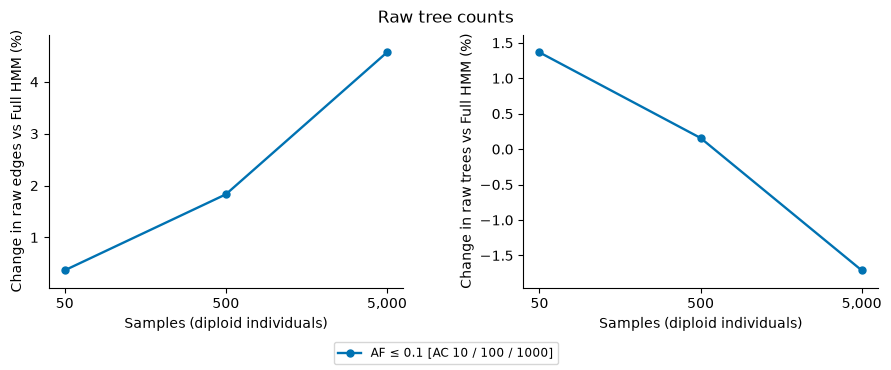

In [17]:
if __name__ == "__main__":
    dated = nb_utils.perf_scaling_date_all(config)
    ipython_display.display(
        dated[
            [
                "dataset",
                "method",
                "af_cutoff",
                "raw_sites",
                "dated_sites",
                "num_edges",
                "num_trees",
                "benchmark_paths_identical",
            ]
        ]
    )
    metrics = {
        "edges_change_percentage": "Change in raw edges vs Full HMM (%)",
        "trees_change_percentage": "Change in raw trees vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            dated,
            metrics,
            "Raw tree counts",
            zoom=True,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "raw_tree_counts",
        export_dpi=180,
    )

## Mutation ages: linear and rank correlation

Posterior **mutation means** (`mn`) are compared with simulated event times
and with Full HMM posterior means. Full HMM is a comparison method, not truth.

For each cohort, use one common variant intersection across Full HMM, the
stitched run and truth. Match position and ancestral/derived
states; exclude recurrent/back-mutation sites and nonfinite ages. All methods,
reference comparisons and frequency bins use that same cohort intersection.
The cached tables include its retention relative to each candidate set.

Pearson r uses untransformed ages in generations. Spearman rank correlation
compares age ordering using average ranks for tied ages. DAF is fixed from Full
HMM for every method; it is distinct from the AF cutoff used to select focal
ancestors. Bin boundaries enter the upper bin. Empty or constant-age bins
have undefined correlation and remain blank in the plots.

Mutation-age comparison complete: out_of_africa_n50_28_1mbp_error


Mutation-age comparison complete: out_of_africa_n500_28_1mbp_error


Mutation-age comparison complete: out_of_africa_n5000_28_1mbp_error


frequency_bin,0.01 ≤ DAF < 0.5,DAF < 0.01,DAF ≥ 0.5,all
dataset,,,,
out_of_africa_n5000_28_1mbp_error,51806,378567,3267,433640
out_of_africa_n500_28_1mbp_error,71708,102973,7008,181689
out_of_africa_n50_28_1mbp_error,76330,0,14211,90541


,dataset,method,af_cutoff,finite_single_mutation_sites,common_mutations,retained_percentage
0,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490669,433640,88.38
1,out_of_africa_n5000_28_1mbp_error,greedy,0.1,440159,433640,98.52
2,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207967,181689,87.36
3,out_of_africa_n500_28_1mbp_error,greedy,0.1,183152,181689,99.20
4,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94664,90541,95.64
5,out_of_africa_n50_28_1mbp_error,greedy,0.1,90848,90541,99.66


,dataset,num_samples,method,af_cutoff,reference_method,frequency_bin,matched_mutations,pearson_r,spearman_r,mean_error_generations,median_absolute_error_generations,mean_estimated_age,mean_reference_age
0,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,all,90541,0.7172,0.8509,-1083.4078,2140.7584,10064.5666,11147.9744
4,out_of_africa_n50_28_1mbp_error,50,greedy,0.1,truth,all,90541,0.7081,0.8509,-975.5696,2128.5587,10172.4048,11147.9744
8,out_of_africa_n50_28_1mbp_error,50,greedy,0.1,full_hmm,all,90541,0.9767,0.9910,107.8382,211.6538,10172.4048,10064.5666
12,out_of_africa_n500_28_1mbp_error,500,full_hmm,NaN,truth,all,181689,0.7503,0.8473,-281.6624,406.4138,3945.7693,4227.4317
16,out_of_africa_n500_28_1mbp_error,500,greedy,0.1,truth,all,181689,0.7138,0.8416,-218.5007,397.3434,4008.9310,4227.4317
20,out_of_africa_n500_28_1mbp_error,500,greedy,0.1,full_hmm,all,181689,0.9519,0.9814,63.1617,109.9374,4008.9310,3945.7693
24,out_of_africa_n5000_28_1mbp_error,5000,full_hmm,NaN,truth,all,433640,0.6955,0.7183,-233.2023,97.6532,1080.5226,1313.7249
28,out_of_africa_n5000_28_1mbp_error,5000,greedy,0.1,truth,all,433640,0.5778,0.7048,-220.3601,97.6414,1093.3648,1313.7249
32,out_of_africa_n5000_28_1mbp_error,5000,greedy,0.1,full_hmm,all,433640,0.8770,0.9592,12.8422,38.6293,1093.3648,1080.5226


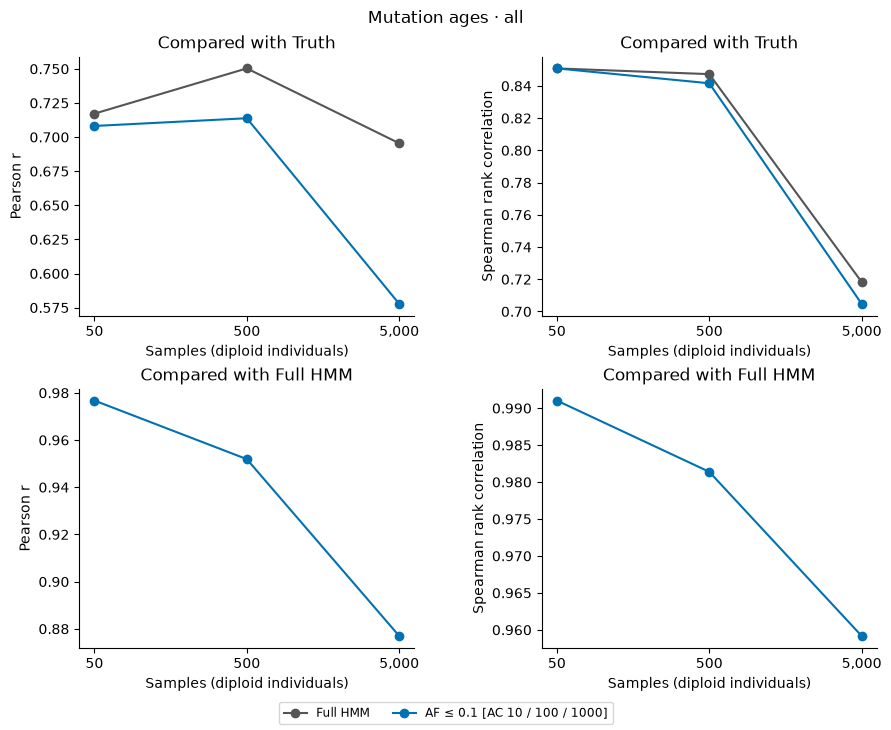

In [18]:
if __name__ == "__main__":
    ages = nb_utils.perf_scaling_mutation_correlations(config, dated)
    checks = ages.groupby(["dataset", "frequency_bin"]).matched_mutations.agg(
        ["min", "max"]
    )
    assert checks["min"].eq(checks["max"]).all()
    ipython_display.display(
        checks["min"].rename("matched_mutations").unstack("frequency_bin")
    )
    retention_paths = sorted(
        (config["cache_dir"] / "age_pairs").glob("*_retention.csv")
    )
    retention = pd.concat(
        [pd.read_csv(path) for path in retention_paths], ignore_index=True
    )
    ipython_display.display(retention.round(2))
    ipython_display.display(ages.loc[ages.frequency_bin.eq("all")].round(4))
    age_metrics = {"pearson_r": "Pearson r", "spearman_r": "Spearman rank correlation"}
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_correlations(
            plot_data,
            ages,
            metrics=age_metrics,
            cohort_labels={},
            cutoff_colors=["#0072B2"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "mutation_age_correlations",
        export_dpi=180,
    )

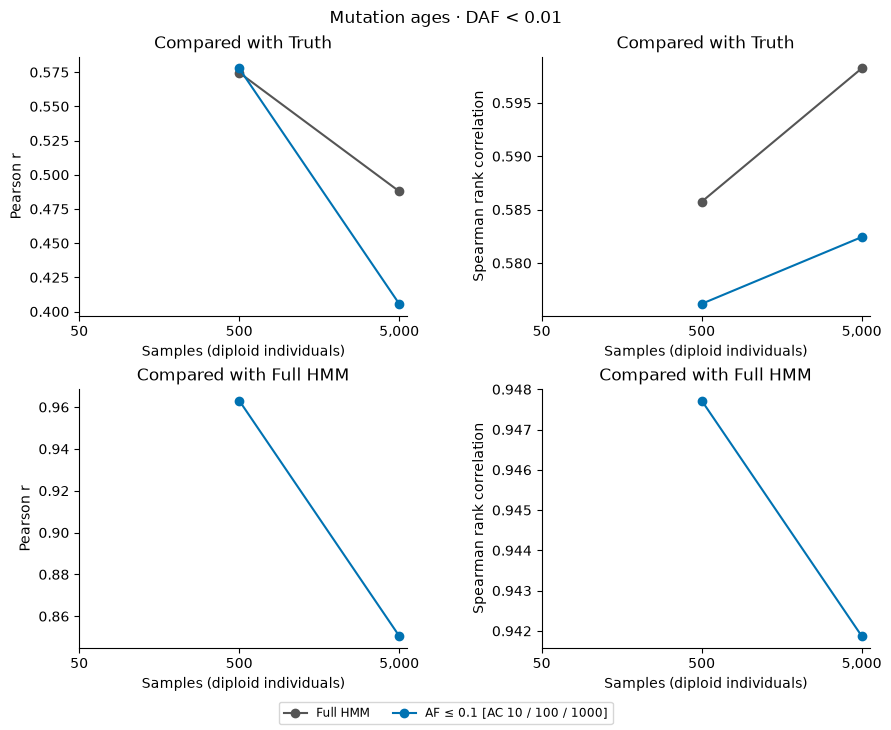

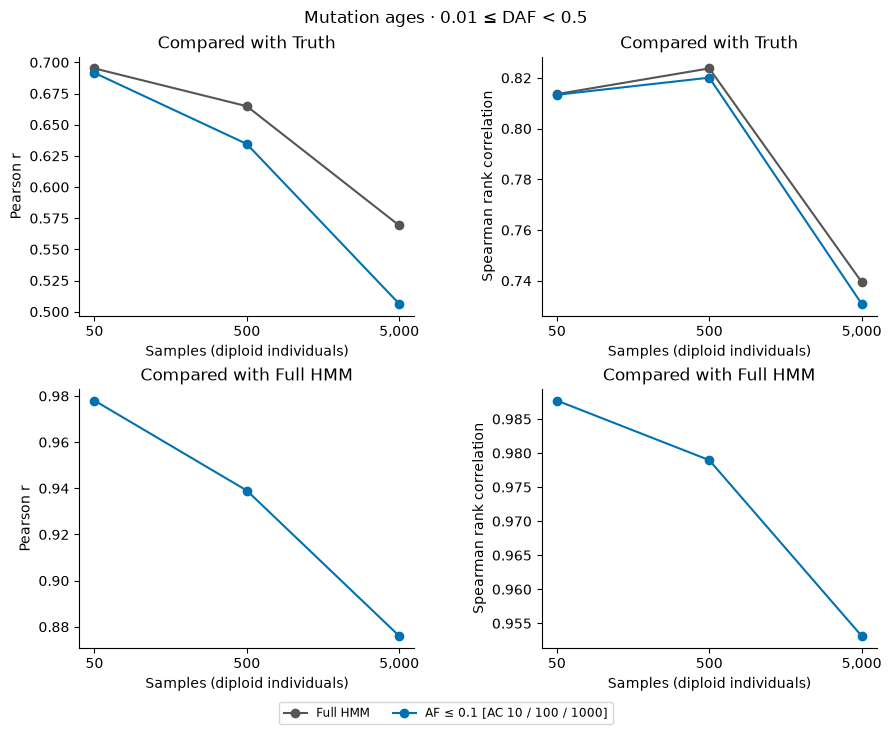

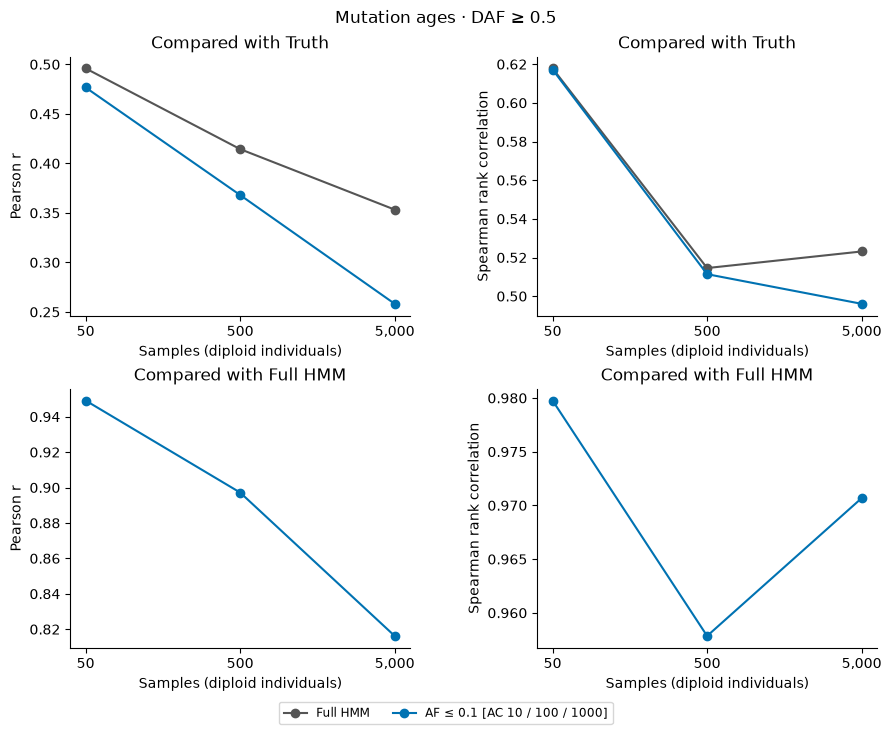

In [19]:
if __name__ == "__main__":
    for index, label in enumerate(config["frequency_bins"]["labels"]):
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_correlations(
                plot_data,
                ages,
                label,
                metrics=age_metrics,
                cohort_labels={},
                cutoff_colors=["#0072B2"],
                full_color="#555555",
                line_width=1.7,
                marker="o",
                marker_size=5,
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=4.4,
                real_data_marker="o",
                sample_tick_alignments={
                    "tgp_chr20p_n3202": "right",
                    "out_of_africa_n5000_28_1mbp_error": "left",
                },
                sample_tick_rotation=0,
            ),
            f"mutation_age_daf_{index}",
            export_dpi=180,
        )

## Paired mutation ages

Hexagons show counts with one shared logarithmic colour scale. The dashed
line is equality. Display bounds omit ages below one generation and use a
shared upper quantile; correlations above use all matched ages,
including display tails. The annotated N is the complete common intersection.

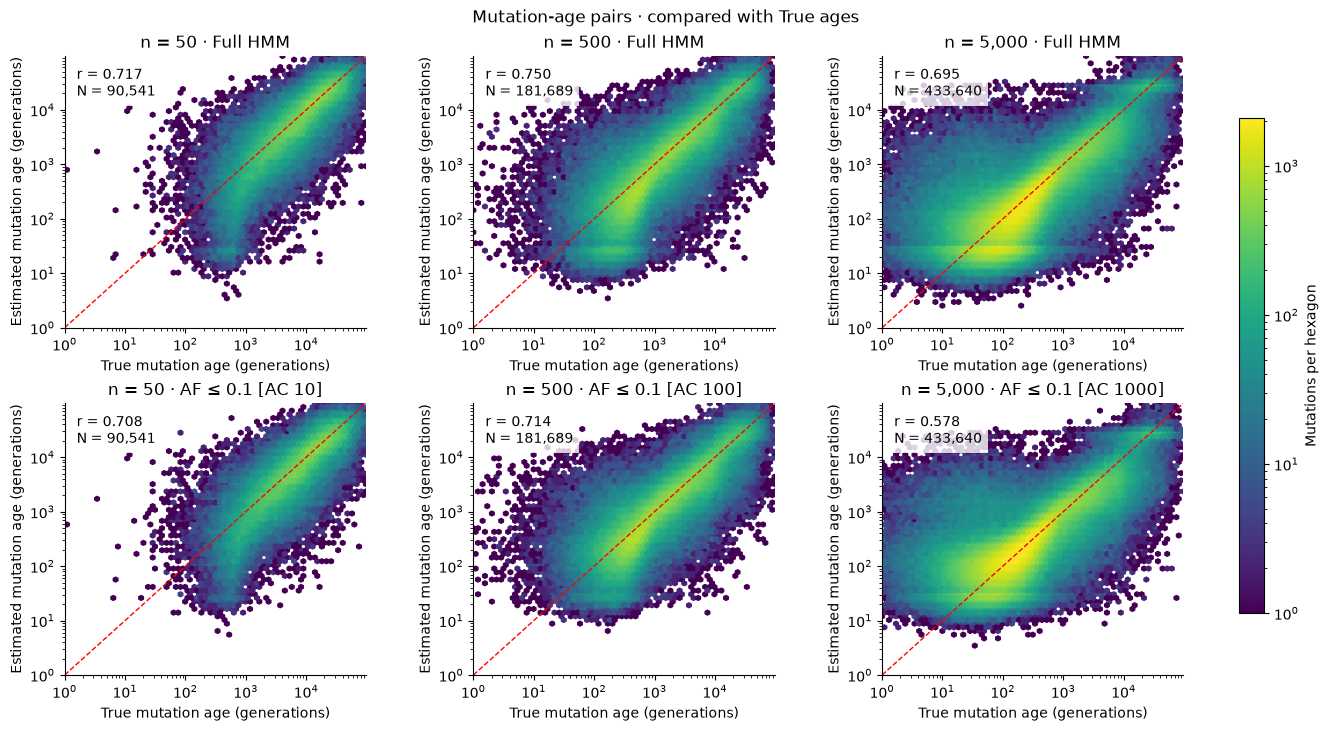

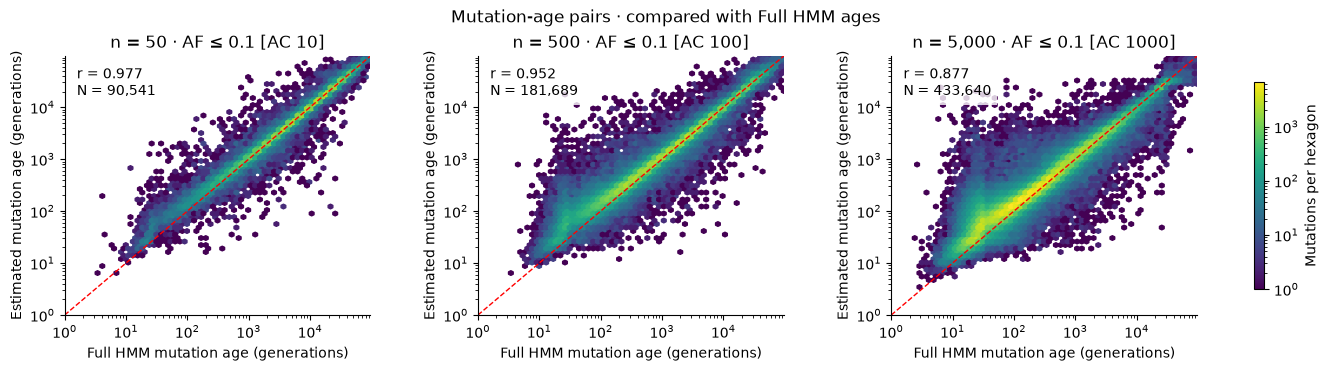

In [20]:
if __name__ == "__main__":
    if cohorts.has_truth.all():
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_density(
                plot_data,
                ages,
                "truth",
                age_hexbin_gridsize=65,
                age_maximum_quantile=0.999,
                age_minimum=1,
                cohort_labels={},
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=4.4,
            ),
            "mutation_ages_vs_truth",
            export_dpi=180,
        )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_density(
            plot_data,
            ages,
            "full_hmm",
            age_hexbin_gridsize=65,
            age_maximum_quantile=0.999,
            age_minimum=1,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "mutation_ages_vs_full_hmm",
        export_dpi=180,
    )